# Decoding tutorial: reconstructing a budgerigar's voice from its vocal-motor cortex

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/urancon/deepSTRF/blob/develop/examples/decoding_tutorial_yang2025.ipynb)

Most of deepSTRF is about **encoding**: predicting neural responses from a stimulus.
This tutorial covers the other direction, **decoding**: predicting the sound from the
neural activity. It walks through the whole decoding API on the
[Yang 2025](../md/README_Yang_2025.md) dataset — single units in the anterior
arcopallium (AAC) of budgerigars, a vocal-motor area, recorded while the birds
sing, together with the bird's own voice from a piezo microphone on the skull.

You will

1. load the dataset and check how the spikes line up with the voice,
2. fit a linear decoder (`WienerFilter`) and a control that ignores the spikes (`MeanTargetBaseline`),
3. write your own non-linear decoder (a small GRU) and train it with `Fitter`,
4. compare the three on held-out vocalisations.

See the [Decoding](../md/decoding.md) page for the reference documentation.

## Setup — Google Colab

On Colab the cell below installs deepSTRF from source; on a local install it does nothing.

**Data credit**: Yang, Z. & Long, M. A. (2025). Convergent vocal representations
in parrot and human forebrain motor networks. *Nature* 640, 427–434. Data on
[Zenodo](https://doi.org/10.5281/zenodo.14057061), licensed CC BY 4.0.

In [1]:
import sys
if 'google.colab' in sys.modules:
    !pip install -q git+https://github.com/urancon/deepSTRF.git@develop
    print("deepSTRF installed from GitHub.")
else:
    print("Local environment — assuming deepSTRF is already importable.")

Local environment — assuming deepSTRF is already importable.


In [2]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm in a plain kernel

import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from deepSTRF.datasets.audio import Yang2025Dataset
from deepSTRF.metrics import mel_cepstral_distortion, spectrogram_corrcoef
from deepSTRF.models.audio.decoding import (
    AudioDecodingModel, MeanTargetBaseline, WienerFilter, valid_time_mask)
from deepSTRF.training import Fitter
from deepSTRF.utils import neural_collate

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
BIRD = "Bl122"
torch.manual_seed(0)
print("device:", DEVICE)

device: mps


## 1. The dataset

`download=True` fetches only the needed files (about 3.3 GB) from the 15.7 GB Zenodo
archive and builds a ~100 MB cache of the vocal episodes. Each item is one warble
bout or call, cut into pieces of at most 5 s, and starts 300 ms before the vocal onset.

- `stims` is the decoding **target**: a `(1, F, T)` log-mel spectrogram of the bird's voice.
- `responses` is the decoder **input**: spike counts of every unit, `(1, T)` each.

Each bird is a separate population, so we work with one bird; the dataset ships a fixed
train / val / test split in `stim_meta['split']`.

In [3]:
def subset(split=None, bird=BIRD):
    ds = Yang2025Dataset(download=True)
    ds.select_pop_by_nrn_attr("bird", bird)            # one bird = one population
    if split is not None:
        ds.select_stims_by_attr("split", split)
    return ds

ds = subset()
train, val, test = subset("train"), subset("val"), subset("test")
N, F = train.n_selected, train.F
print(f"{BIRD}: {N} units, {F} mel bands, dt = {ds.dt} ms")
print(f"items: train {len(train)}, val {len(val)}, test {len(test)}")

Bl122: 43 units, 32 mel bands, dt = 5.0 ms


items: train 67, val 17, test 19


### Spikes and voice

One warble item: the log-mel (top), the spike raster (middle, one row per unit), and
the population rate against the vocal envelope (bottom, both z-scored).

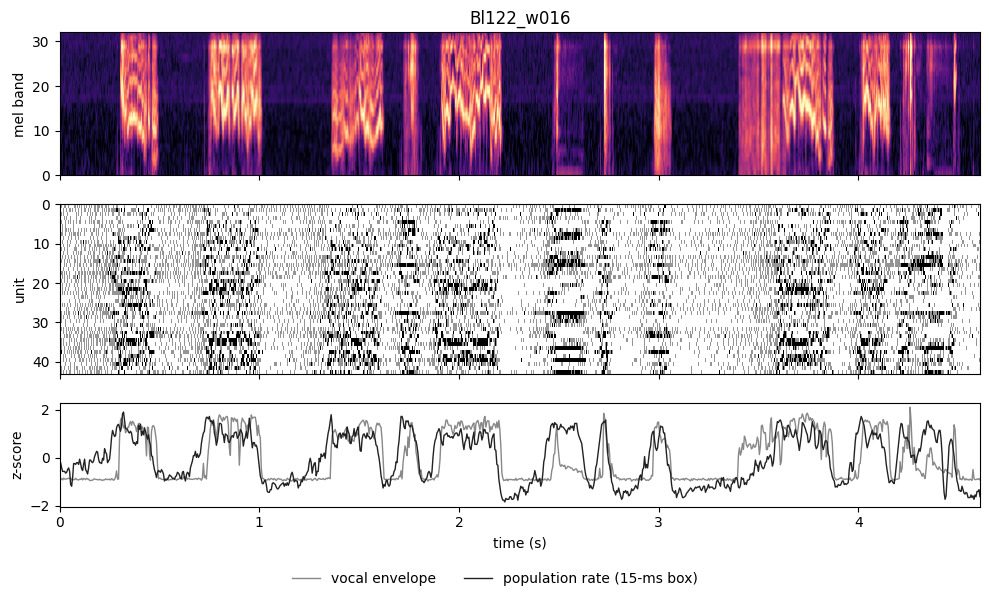

In [4]:
units = ds._selected()
items = [s for s, m in enumerate(ds.stim_meta) if m["bird"] == BIRD]
s = max((s for s in items if ds.stim_meta[s]["split"] == "test"
         and ds.stim_meta[s]["episode_type"] == "warble"), key=lambda s: ds.stims[s].shape[-1])

def rate_and_envelope(s):
    rate = torch.cat([ds.responses[s][n] for n in units]).sum(0).numpy()   # spikes / bin
    env = torch.logsumexp(ds.stims[s][0], dim=0).numpy()                    # log total power
    return rate, env

z = lambda x: (x - x.mean()) / (x.std() + 1e-12)
spec, spikes = ds.stims[s][0].numpy(), torch.cat([ds.responses[s][n] for n in units]).numpy()
rate, env = rate_and_envelope(s)
t = np.arange(spec.shape[-1]) * ds.dt / 1000

fig, (a0, a1, a2) = plt.subplots(3, 1, figsize=(10, 6), sharex=True,
                                 gridspec_kw=dict(height_ratios=[1.1, 1.3, 0.8]))
a0.imshow(spec, origin="lower", aspect="auto", cmap="magma", extent=[0, t[-1], 0, F],
          vmin=np.percentile(spec, 2), vmax=np.percentile(spec, 99.5))
a0.set_ylabel("mel band"); a0.set_title(ds.stim_meta[s]["bout_id"])
a1.imshow(np.minimum(spikes, 2), aspect="auto", cmap="Greys", interpolation="nearest",
          extent=[0, t[-1], len(units), 0], vmin=0, vmax=2)
a1.set_ylabel("unit")
a2.plot(t, z(env), color="#888888", lw=1, label="vocal envelope")
a2.plot(t, z(np.convolve(rate, np.ones(3) / 3, mode="same")), color="#222222", lw=1,
        label="population rate (15-ms box)")
a2.set_ylabel("z-score"); a2.set_xlabel("time (s)"); a2.set_xlim(0, t[-1])
fig.legend(*a2.get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

The population fires during each vocal burst and falls silent in between. To see
*when*, we correlate the population rate with the envelope at a range of lags, over
all of the bird's items. Positive lags mean the spikes come **before** the sound.
The grey band is a null: 20 random circular shifts of the rate within each item.

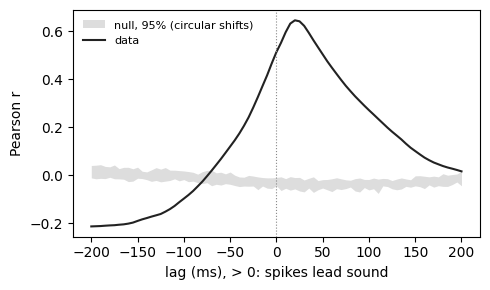

peak at +20 ms (r = 0.65)


In [5]:
MAXLAG = 40                                                  # bins = 200 ms
lags_ms = np.arange(-MAXLAG, MAXLAG + 1) * ds.dt
pairs = [tuple(z(x) for x in rate_and_envelope(s)) for s in items]

def xcorr(pairs, rng=None):
    out = []
    for lag in range(-MAXLAG, MAXLAG + 1):
        a, b = [], []
        for r, e in pairs:
            if rng is not None:
                r = np.roll(r, rng.integers(MAXLAG, max(MAXLAG + 1, len(r) - MAXLAG)))
            T = len(e)
            a.append(r[: T - lag] if lag >= 0 else r[-lag:])
            b.append(e[lag:] if lag >= 0 else e[: T + lag])
        out.append(np.corrcoef(np.concatenate(a), np.concatenate(b))[0, 1])
    return np.array(out)

r = xcorr(pairs)
rng = np.random.default_rng(0)
null = np.stack([xcorr(pairs, rng) for _ in range(20)])
fig, ax = plt.subplots(figsize=(5, 3))
ax.fill_between(lags_ms, *np.percentile(null, [2.5, 97.5], axis=0), color="#dddddd", lw=0,
                label="null, 95% (circular shifts)")
ax.plot(lags_ms, r, color="#222222", label="data")
ax.axvline(0, color="#888888", ls=":", lw=0.8)
ax.set_xlabel("lag (ms), > 0: spikes lead sound"); ax.set_ylabel("Pearson r")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()
print(f"peak at {lags_ms[np.argmax(r)]:+.0f} ms (r = {r.max():.2f})")

The activity **leads** the voice by a few tens of milliseconds, as expected for a
vocal-motor area. A decoder should therefore be **causal**: predict the sound at time
*t* from the spikes up to *t*.

## 2. A linear decoder and a control

The `WienerFilter` predicts each mel band as a weighted sum of all units' activity over
the last `n_lags` bins (`lag_offset=0`, the default, makes it causal). It is fitted in
closed form by ridge regression; we choose the ridge strength on the validation set.

The `MeanTargetBaseline` ignores the spikes and predicts the average training
spectrogram, aligned on item onset. Any decoder must beat it to show that it uses the
neural activity.

In [6]:
loader = lambda d, shuffle=False, bs=8: DataLoader(d, batch_size=bs, shuffle=shuffle,
                                                  collate_fn=neural_collate)

def evaluate(model, d):
    """Per-band r of the log-mel (mean over bands) on all frames and on the vocal span only,
    plus mel-cepstral distortion. Returns the predictions too."""
    b = next(iter(loader(d, bs=len(d))))
    with torch.no_grad():
        pred = model.cpu().eval()(b["responses"])
    m_all = valid_time_mask(b["responses"])
    m_voc = m_all.clone()
    for i, meta in enumerate(b["stim_meta"]):      # mask the 300-ms pre-roll
        m_voc[i, : int(round((meta["vocal_onset_s"] - meta["t_start_s"]) * 1000 / d.dt))] = False
    m_all, m_voc = m_all[:, None, None, :], m_voc[:, None, None, :]
    return dict(r_all=float(spectrogram_corrcoef(pred, b["stims"], mask=m_all)),
                r_vocal=float(spectrogram_corrcoef(pred, b["stims"], mask=m_voc)),
                mcd=float(mel_cepstral_distortion(pred, b["stims"], mask=m_all))), pred, b

val_r = {}
for alpha in (1e2, 1e3, 1e4, 1e5):
    val_r[alpha] = evaluate(WienerFilter(N, F, n_lags=40).fit(loader(train), alpha=alpha), val)[0]["r_all"]
    print(f"alpha {alpha:.0e}: val r = {val_r[alpha]:.3f}")
alpha = max(val_r, key=val_r.get)

models = {"control": MeanTargetBaseline(N, F).fit(loader(train)),
          "Wiener": WienerFilter(N, F, n_lags=40).fit(loader(train), alpha=alpha)}

alpha 1e+02: val r = 0.729


alpha 1e+03: val r = 0.733


alpha 1e+04: val r = 0.744


alpha 1e+05: val r = 0.726


## 3. Your own decoder

Any decoder subclasses `AudioDecodingModel` and implements `decode(x)`, which maps the
repeat-averaged activity `(B, N, T)` to a spectrogram `(B, 1, F, T)`. Here: a small
recurrent network (dropout → linear → ELU → GRU → linear). A GRU only looks at the
past, so it is causal.

`Fitter` reads `model.direction == "decoding"` and swaps input and target by itself:
it feeds `batch['responses']` to the model, compares the output with `batch['stims']`,
ignores padded frames, and early-stops on the validation per-band correlation. We keep
the best-on-validation weights (`ckpt_path`). This takes a few minutes on a GPU or an
Apple-silicon Mac, longer on a CPU.

In [7]:
class GRUDecoder(AudioDecodingModel):
    def __init__(self, n_neurons, n_frequency_bands, hidden=64, dropout=0.3):
        super().__init__(n_neurons, n_frequency_bands)
        self.inp = nn.Sequential(nn.Dropout(dropout), nn.Linear(n_neurons, hidden), nn.ELU())
        self.core = nn.GRU(hidden, hidden, batch_first=True)
        self.readout = nn.Linear(hidden, n_frequency_bands)
        self.validate()

    def decode(self, x):                                   # x: (B, N, T) spike counts
        h, _ = self.core(self.inp(torch.log1p(x).transpose(1, 2)))
        return self.readout(h).transpose(1, 2).unsqueeze(1)   # (B, 1, F, T)

gru = GRUDecoder(N, F)
with torch.no_grad():   # start from the mean log-mel of each band
    gru.readout.bias.copy_(torch.cat([train[i]["stims"][0] for i in range(len(train))], 1).mean(1))

def log_every_10(e):
    if e["epoch"] % 10 == 0:
        print(f"epoch {e['epoch']:3d}  train loss {e['train_loss']:.3f}  "
              f"val r {float(torch.nanmean(torch.as_tensor(e['val_cc']))):.3f}")

ckpt = Path(tempfile.mkdtemp()) / "gru_best.pt"
fitter = Fitter(gru, loader(train, shuffle=True), loader(val), device=DEVICE,
                optimizer=torch.optim.AdamW(gru.parameters(), lr=3e-3, weight_decay=1e-2),
                max_epochs=10_000, patience=30, ckpt_path=ckpt,
                track_train_metrics=False, log_fn=log_every_10)
history = fitter.fit()
print(f"stopped after {len(history)} epochs; best-on-val weights restored")
models["GRU"] = gru

epoch   0  train loss 17.437  val r 0.574


epoch  10  train loss 8.962  val r 0.711


epoch  20  train loss 7.738  val r 0.752


epoch  30  train loss 7.299  val r 0.766


epoch  40  train loss 6.992  val r 0.767


epoch  50  train loss 6.594  val r 0.779


... (7 outputs left out)

epoch 130  train loss 5.276  val r 0.780


epoch 140  train loss 5.266  val r 0.775


epoch 150  train loss 5.066  val r 0.778


stopped after 156 epochs; best-on-val weights restored


## 4. Comparison on held-out vocalisations

We score each model on the test items with the per-band Pearson r of the log-mel
(averaged over bands), on all frames and on the vocal span only (pre-roll masked), and
with the mel-cepstral distortion (MCD, lower is better).

control  r (all) 0.081   r (vocal) 0.015   MCD 60.9 dB
Wiener   r (all) 0.738   r (vocal) 0.746   MCD 44.7 dB
GRU      r (all) 0.774   r (vocal) 0.782   MCD 41.0 dB


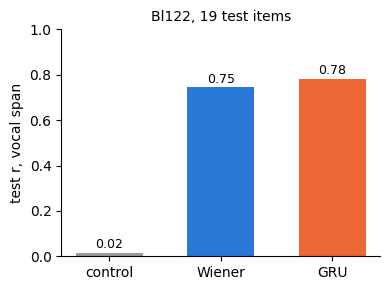

In [8]:
scores, preds = {}, {}
for name, m in models.items():
    scores[name], preds[name], batch = evaluate(m, test)
    print(f"{name:8s} r (all) {scores[name]['r_all']:.3f}   r (vocal) {scores[name]['r_vocal']:.3f}   "
          f"MCD {scores[name]['mcd']:.1f} dB")

colors = {"control": "#9a9a9a", "Wiener": "#2a78d6", "GRU": "#eb6834"}
fig, ax = plt.subplots(figsize=(4, 3))
for k, name in enumerate(models):
    ax.bar(k, scores[name]["r_vocal"], color=colors[name], width=0.6)
    ax.text(k, scores[name]["r_vocal"] + 0.02, f"{scores[name]['r_vocal']:.2f}", ha="center", fontsize=9)
ax.set_xticks(range(len(models)), list(models)); ax.set_ylim(0, 1)
ax.set_ylabel("test r, vocal span"); ax.set_title(f"{BIRD}, {len(test)} test items", fontsize=10)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

Both decoders are far above the control, so their predictions come from the spikes.
On this bird the GRU adds a few hundredths of correlation over the linear filter
(one training seed; across the four birds the gain is +0.03 to +0.07).

Finally, the longest test warble item: the true spectrogram and the two
reconstructions, on a shared colour scale.

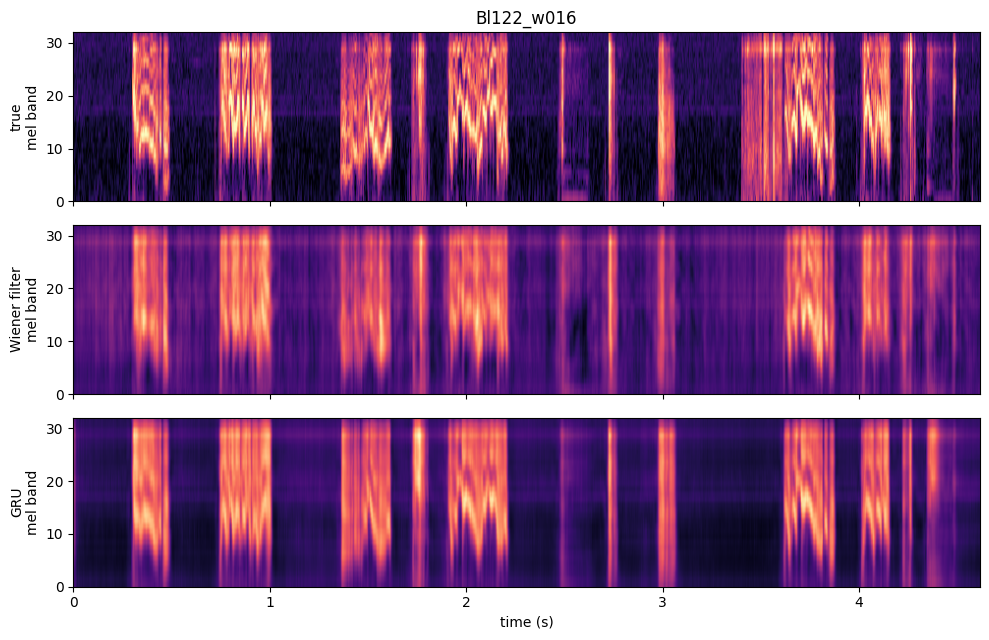

In [9]:
i = max((k for k, m in enumerate(batch["stim_meta"]) if m["episode_type"] == "warble"),
        key=lambda k: int(valid_time_mask(batch["responses"])[k].sum()))
T = int(valid_time_mask(batch["responses"])[i].sum())
true = batch["stims"][i, 0, :, :T].numpy()
vmin, vmax = np.percentile(true, [2, 99.5])
fig, axes = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True, sharey=True)
for ax, (title, img) in zip(axes, [("true", true), ("Wiener filter", preds["Wiener"][i, 0, :, :T].numpy()),
                                   ("GRU", preds["GRU"][i, 0, :, :T].numpy())]):
    ax.imshow(img, origin="lower", aspect="auto", cmap="magma", vmin=vmin, vmax=vmax,
              extent=[0, T * test.dt / 1000, 0, F])
    ax.set_ylabel(f"{title}\nmel band")
axes[0].set_title(batch["stim_meta"][i]["bout_id"]); axes[-1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

## Next steps

- Change `BIRD` to `"Ti81"`, `"Li145"` or `"Or61"`: each bird is its own population.
- Score calls and warble separately with `select_stims_by_attr("episode_type", "call")`.
- Any `AudioDecodingModel` subclass trains with `Fitter` exactly like the GRU above.
- The [Decoding](../md/decoding.md) page lists the decoding models and metrics, and the
  [Yang 2025](../md/README_Yang_2025.md) page documents the dataset, its items and splits,
  and its license.